# Relatório de análise SteamDB

## Resumo

- A base MySQL contém **114.172 jogos**, com datas de lançamento de 1997 a janeiro de 2026.
- Os lançamentos registrados passaram de **8.733 em 2020** para **21.680 em 2025**. O ano de 2026 está incompleto na base e não deve ser comparado como ano fechado.
- As tabelas de associação contêm **637.678 vínculos jogo–idioma** e **151.023 vínculos jogo–plataforma**.
- As avaliações positivas são muito concentradas: poucos jogos atingem milhões de avaliações. Os gráficos logarítmico e boxplot mostram essa diferença de escala.

Este relatório reúne as consultas usadas nos scripts de análise e na verificação das chaves. As imagens originais estão incorporadas ao notebook.

## Contexto e método

**Fonte:** banco MySQL `steamdb`, tabelas `jogos`, `idiomas`, `plataformas`, `jogos_idiomas` e `jogos_plataformas`. Os scripts de origem estão em `../src/analises/`, `../src/carga/` e `../sql/consultas/`. Os gráficos incorporados vieram de `../resultados/graficos/`.

**Definições:** lançamento por ano usa `YEAR(data_lancamento)`; mediana de preço usa todos os jogos do ano, inclusive gratuitos; as estatísticas de tempo consideram apenas `tempo_medio_jogo > 0`. A planilha de origem chega apenas até 05/01/2026. Há 47 nomes de idioma sem correspondência no catálogo, registrados em `../resultados/relatorios/idiomas_nao_mapeados.csv` e excluídos das associações.

Para executar, instale `requirements.txt`, configure `.env` na raiz com as variáveis `MYSQL_*` e selecione o ambiente Python do projeto como kernel. As consultas abaixo são somente de leitura.

### Conectar ao banco

In [1]:
import os
from pathlib import Path

import mysql.connector
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display


def encontrar_raiz(inicio=Path.cwd()):
    for pasta in (inicio, *inicio.parents):
        if (pasta / '.env.example').exists() and (pasta / 'sql').is_dir():
            return pasta
    raise FileNotFoundError('Abra o notebook dentro do repositório analise-steamdb-senac.')


RAIZ = encontrar_raiz()
load_dotenv(RAIZ / '.env')


def consultar(sql):
    conexao = mysql.connector.connect(
        host=os.environ['MYSQL_HOST'],
        user=os.environ['MYSQL_USER'],
        password=os.environ['MYSQL_PASSWORD'],
        database=os.environ['MYSQL_DATABASE'],
    )
    try:
        cursor = conexao.cursor()
        try:
            cursor.execute(sql)
            return pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)
        finally:
            cursor.close()
    finally:
        conexao.close()


## Dados

### Tamanho e período da base

A primeira consulta confere a quantidade de jogos e os limites das datas e dos preços.

In [2]:
sql_resumo = '''
SELECT COUNT(*) AS total_jogos,
       MIN(data_lancamento) AS primeira_data,
       MAX(data_lancamento) AS ultima_data,
       MIN(preco) AS preco_minimo,
       MAX(preco) AS preco_maximo
FROM jogos
'''
display(consultar(sql_resumo))

,total_jogos,primeira_data,ultima_data,preco_minimo,preco_maximo
0,114172,1997-06-30,2026-01-05,0.00,999.98


## Resultados

### Lançamentos por ano

A consulta agrupa os jogos pelo ano da data de lançamento. O gráfico mostra crescimento no período recente; os 84 registros de 2026 representam apenas o trecho disponível da base.

In [3]:
sql_lancamentos = '''
SELECT YEAR(data_lancamento) AS ano,
       COUNT(*) AS jogos_lancados
FROM jogos
GROUP BY YEAR(data_lancamento)
ORDER BY ano
'''
lancamentos = consultar(sql_lancamentos)
display(lancamentos.tail(12))

qtd_2020 = int(lancamentos.loc[lancamentos['ano'] == 2020, 'jogos_lancados'].iloc[0])
qtd_2025 = int(lancamentos.loc[lancamentos['ano'] == 2025, 'jogos_lancados'].iloc[0])
print(f'2020: {qtd_2020:,} | 2025: {qtd_2025:,} | variação: {(qtd_2025 / qtd_2020 - 1) * 100:.1f}%')

,ano,jogos_lancados
18,2015,2499
19,2016,4133
20,2017,5910
21,2018,7419
22,2019,7230
23,2020,8733
24,2021,10379
25,2022,11345
26,2023,13287
27,2024,18046


2020: 8,733 | 2025: 21,680 | variação: 148.3%


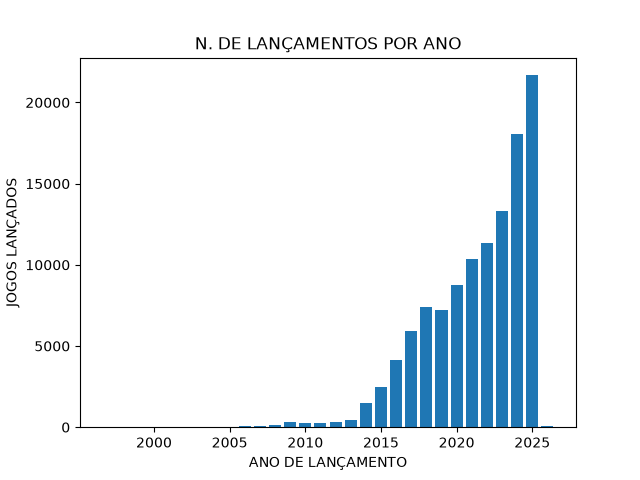

*Número de lançamentos por ano*

### Mediana do preço por ano

A consulta traz ano e preço; a mediana é calculada em Python porque os scripts do projeto já usam essa medida. A mediana reduz a influência de preços extremos. O gráfico inclui jogos gratuitos, portanto não representa apenas o mercado pago.

In [4]:
sql_precos_ano = '''
SELECT YEAR(data_lancamento) AS ano,
       preco
FROM jogos
WHERE data_lancamento IS NOT NULL
'''
precos_ano = consultar(sql_precos_ano)
precos_ano['preco'] = pd.to_numeric(precos_ano['preco'])
medianas_ano = (
    precos_ano.groupby('ano', as_index=False)['preco']
    .median()
    .rename(columns={'preco': 'mediana_preco'})
)
display(medianas_ano.tail(12))

,ano,mediana_preco
18,2015,2.49
19,2016,2.49
20,2017,2.09
21,2018,1.99
22,2019,2.09
23,2020,2.09
24,2021,1.99
25,2022,2.49
26,2023,2.74
27,2024,2.99


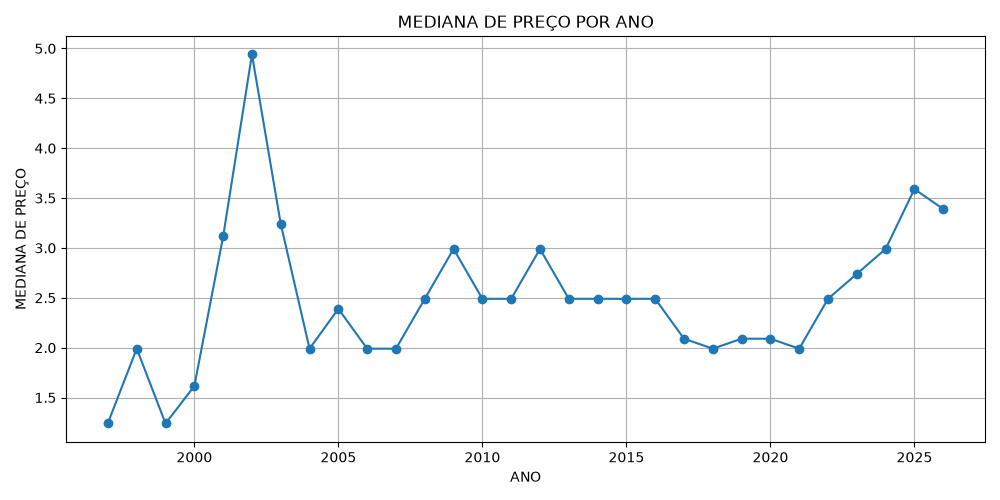

*Mediana do preço por ano*

### Avaliações positivas

A consulta lê a contagem de avaliações positivas por jogo. No primeiro gráfico, `log(1 + avaliações)` permite ver jogos com poucas e muitas avaliações na mesma escala. O boxplot evidencia valores extremos; por isso média e mediana devem ser interpretadas juntas.

In [5]:
sql_avaliacoes = '''
SELECT avaliacoes_positivas
FROM jogos
WHERE avaliacoes_positivas IS NOT NULL
'''
avaliacoes = pd.to_numeric(consultar(sql_avaliacoes)['avaliacoes_positivas'])
display(pd.DataFrame({
    'medida': ['jogos', 'média', 'mediana', 'máximo', 'assimetria'],
    'valor': [len(avaliacoes), avaliacoes.mean(), avaliacoes.median(),
              avaliacoes.max(), avaliacoes.skew()],
}))

,medida,valor
0,jogos,1.141720e+05
1,média,1.087548e+03
2,mediana,7.000000e+00
3,máximo,7.642084e+06
4,assimetria,1.763088e+02


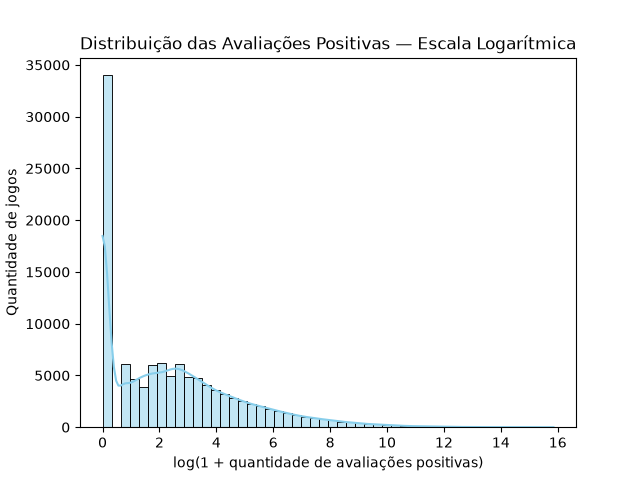

*Distribuição das avaliações positivas em escala logarítmica*

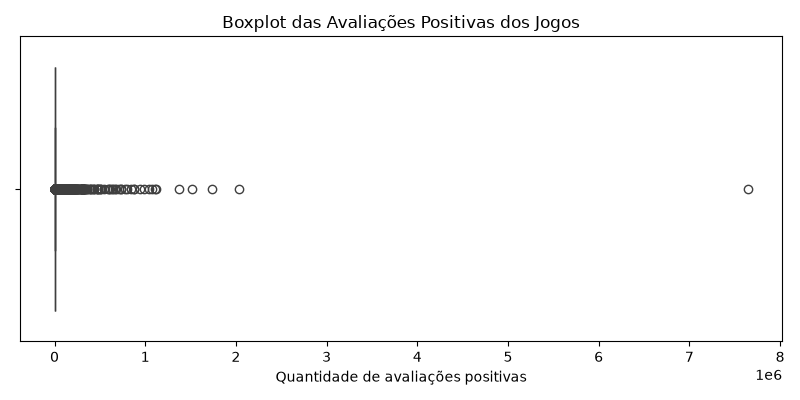

*Boxplot das avaliações positivas*

### Preços de jogos pagos

Esta consulta reproduz o filtro `preco > 0` usado no script de média e mediana. Seus resultados têm uma população diferente da mediana anual acima, que inclui preços zero.

In [6]:
sql_precos_pagos = '''
SELECT preco
FROM jogos
WHERE preco > 0
'''
precos_pagos = pd.to_numeric(consultar(sql_precos_pagos)['preco'])
display(pd.DataFrame({
    'medida': ['jogos pagos', 'preço médio', 'preço mediano'],
    'valor': [len(precos_pagos), precos_pagos.mean(), precos_pagos.median()],
}))

,medida,valor
0,jogos pagos,96281.000000
1,preço médio,6.055445
2,preço mediano,3.490000


### Quartis da quantidade de DLCs

Como no script de quartis, a consulta considera apenas jogos com pelo menos um DLC. O intervalo interquartil (IQR) separa a metade central dos valores; o limite superior `Q3 + 1,5 × IQR` ajuda a contar valores atípicos.

In [7]:
sql_dlc = '''
SELECT dlc_count
FROM jogos
WHERE dlc_count > 0
'''
dlcs = pd.to_numeric(consultar(sql_dlc)['dlc_count'])
q1, mediana, q3 = dlcs.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
display(pd.DataFrame({
    'medida': ['jogos com DLC', 'Q1', 'mediana', 'Q3', 'IQR', 'acima de Q3 + 1,5 × IQR'],
    'valor': [len(dlcs), q1, mediana, q3, iqr, int((dlcs > q3 + 1.5 * iqr).sum())],
}))

,medida,valor
0,jogos com DLC,17720.0
1,Q1,1.0
2,mediana,1.0
3,Q3,2.0
4,IQR,1.0
5,"acima de Q3 + 1,5 × IQR",2467.0


### Tempo médio de jogo

A consulta calcula média, variância e desvio padrão populacionais em minutos. Jogos com tempo igual a zero ficam fora do cálculo, como no SQL e no script de variância do projeto.

In [8]:
sql_tempo = '''
SELECT COUNT(*) AS quantidade_jogos,
       ROUND(AVG(tempo_medio_jogo), 2) AS media_minutos,
       ROUND(VAR_POP(tempo_medio_jogo), 2) AS variancia_minutos_quadrados,
       ROUND(STDDEV_POP(tempo_medio_jogo), 2) AS desvio_padrao_minutos
FROM jogos
WHERE tempo_medio_jogo > 0
'''
display(consultar(sql_tempo))

,quantidade_jogos,media_minutos,variancia_minutos_quadrados,desvio_padrao_minutos
0,26042,975.36,5.916744e+08,24324.36


### Relações entre jogos, idiomas e plataformas

As duas primeiras consultas conferem o volume de pares e mostram uma amostra de chaves ligadas. Os pares estão armazenados nos CSVs `../dados/tratados/csv/jogos_idiomas.csv` e `../dados/tratados/csv/jogos_plataformas.csv`.

In [9]:
sql_vinculos = '''
SELECT 'jogos_idiomas' AS tabela, COUNT(*) AS vinculos FROM jogos_idiomas
UNION ALL
SELECT 'jogos_plataformas' AS tabela, COUNT(*) AS vinculos FROM jogos_plataformas
'''
display(consultar(sql_vinculos))

,tabela,vinculos
0,jogos_idiomas,637678
1,jogos_plataformas,151023


In [10]:
sql_exemplo_idioma = '''
SELECT j.jogo_id, j.nome AS jogo, i.idioma_id, i.nome AS idioma
FROM jogos AS j
JOIN jogos_idiomas AS ji ON ji.jogo_id = j.jogo_id
JOIN idiomas AS i ON i.idioma_id = ji.idioma_id
WHERE j.jogo_id = 496350
ORDER BY i.nome
'''
sql_exemplo_plataforma = '''
SELECT j.jogo_id, j.nome AS jogo, p.plataforma_id, p.nome AS plataforma
FROM jogos AS j
JOIN jogos_plataformas AS jp ON jp.jogo_id = j.jogo_id
JOIN plataformas AS p ON p.plataforma_id = jp.plataforma_id
WHERE j.jogo_id = 496350
ORDER BY p.nome
'''
display(consultar(sql_exemplo_idioma))
display(consultar(sql_exemplo_plataforma))

,jogo_id,jogo,idioma_id,idioma
0,496350,Supipara - Chapter 1 Spring Has Come!,20,English


,jogo_id,jogo,plataforma_id,plataforma
0,496350,Supipara - Chapter 1 Spring Has Come!,3,Windows


### Integridade das chaves

Cada contagem deve ser zero. As FKs impedem novos vínculos órfãos, e esta consulta verifica o estado atual das tabelas.

In [11]:
sql_orfaos = '''
SELECT 'jogos_idiomas' AS tabela, COUNT(*) AS orfaos
FROM jogos_idiomas AS ji
LEFT JOIN jogos AS j ON j.jogo_id = ji.jogo_id
LEFT JOIN idiomas AS i ON i.idioma_id = ji.idioma_id
WHERE j.jogo_id IS NULL OR i.idioma_id IS NULL
UNION ALL
SELECT 'jogos_plataformas' AS tabela, COUNT(*) AS orfaos
FROM jogos_plataformas AS jp
LEFT JOIN jogos AS j ON j.jogo_id = jp.jogo_id
LEFT JOIN plataformas AS p ON p.plataforma_id = jp.plataforma_id
WHERE j.jogo_id IS NULL OR p.plataforma_id IS NULL
'''
display(consultar(sql_orfaos))

,tabela,orfaos
0,jogos_idiomas,0
1,jogos_plataformas,0


## Conclusões

- A contagem anual mostra **21.680 lançamentos em 2025**, aproximadamente **148% acima de 2020** na base analisada. Isso descreve os registros disponíveis, sem atribuir causa ao crescimento.
- Os gráficos de avaliações mostram uma distribuição muito desigual; os valores extremos tornam a mediana especialmente útil para descrever um jogo típico.
- As consultas das tabelas de associação permitem navegar de cada `jogo_id` aos IDs válidos de idioma e plataforma. Os 47 nomes de idioma não mapeados exigem revisão antes de uma carga completa.
- O relatório pode ser atualizado executando todas as células novamente após uma nova carga no MySQL; os gráficos incorporados representam a versão recebida e não mudam automaticamente.